# ДЗ2 · RAG, Milvus и память

Рабочий прогон: корпус ДЗ1 → две нарезки → recall/гибрид → RAG/агент → память → бонусы.
Тяжёлые замеры уже посчитаны `hw2.py`; здесь — воспроизведение индекса/демо и вывод артефактов.

In [1]:
from pathlib import Path
from IPython.display import display, Markdown, Image
import pandas as pd
import hw2

hw2.connect_milvus()
hw2.load_cache()
print("Milvus:", hw2.MILVUS_MODE)
print("cache keys:", len(hw2.EMB))
print("collections:", hw2.client.list_collections())

Milvus: lite:milvus_lite.db (Docker недоступен — пометка в README)
Milvus: lite:milvus_lite.db
cache keys: 8591
collections: ['chars', 'course', 'facts', 'lines']


## Корпус и нарезки

In [2]:
corpus = hw2.load_jsonl("corpus_2026.jsonl")
tasks = hw2.load_jsonl("questions.jsonl")
unans = hw2.load_jsonl("unanswerable.jsonl")
line_chunks = [c for p in corpus for c in hw2.chunk_lines(p)]
char_chunks = [c for p in corpus for c in hw2.chunk_chars(p)]
print(f"pages={len(corpus)} tasks={len(tasks)} unanswerable={len(unans)}")
print(f"line_chunks={len(line_chunks)} char_chunks={len(char_chunks)}")
assert len(line_chunks) >= 300
tasks[0]

pages=30 tasks=146 unanswerable=10
line_chunks=5839 char_chunks=2122


{'id': 'fresh-0',
 'source': 'fresh',
 'question': 'On what date did Ukraine boycott the closing ceremony of the 2026 Winter Paralympics?',
 'answer': '15 March',
 'evidence': '15 March – Ukraine boycotts the closing ceremony of the 2026 Winter Paralympics in Italy in protest over Russian athletes being allowed to compete under the Russian flag after the lifting of sanctions imposed over the Russian invasion in 2022.',
 'page': '2026 in Ukraine',
 'url': 'https://en.wikipedia.org/wiki/2026_in_Ukraine'}

## Индекс и фильтр по page

In [3]:
hits = hw2.search_milvus("lines", "Masters Tournament McIlroy", 3)
display(pd.DataFrame(hits)[["score", "page", "text"]].assign(text=lambda d: d.text.str[:120]))
flt = hw2.search_milvus("lines", "earthquake magnitude", 5, 'page == "2026 in Japan"')
display(pd.DataFrame(flt)[["score", "page", "text"]].assign(text=lambda d: d.text.str[:120]))

  embedded 1/1


,score,page,text
0,0.552068,2026 in sports,April 9–12: 2026 Masters Tournament at Augusta...
1,0.544732,2026 in the United States,Rory McIlroy wins the Masters Tournament for t...
2,0.442464,2026 in sports,=== Men's major golf championships (PGA Tour) ===


  embedded 1/1


,score,page,text
0,0.460312,2026 in Japan,April 20 – A magnitude 7.7 earthquake hits off...
1,0.457775,2026 in Japan,May 15 – A magnitude 6.3 earthquake strikes of...
2,0.455036,2026 in Japan,A magnitude 5.9 earthquake strikes southern Am...
3,0.435171,2026 in Japan,A magnitude 5.0 earthquake hits southern Tochi...
4,0.428834,2026 in Japan,April 27 – A magnitude 6.1 earthquake strikes ...


## knowledge_base: 3 теста

In [4]:
hw2.register(hw2.knowledge_base, hw2.KBArgs, "Searches the local knowledge base of 2026 events")
ok = hw2.knowledge_base("Masters Tournament Rory McIlroy 2026")
empty = hw2.knowledge_base("Masters", page="ThisPageDoesNotExistXYZ999")
err = hw2.knowledge_base("test", page='broken"quote')
print("OK:\n", ok[:300], "\n")
print("EMPTY:", empty)
print("ERROR:", err[:200])
assert "McIlroy" in ok or "Masters" in ok
assert empty == "nothing found" or empty.strip() == "" or "ошибка" in empty
assert "ошибка" in err or "[" in err or "nothing found" in err
print("knowledge_base tests passed")


  embedded 1/1


  embedded 1/1


  embedded 1/1


2026-09-21 11:00:40,386 [ERROR][_log_rpc_error]: RPC error: [search], <MilvusException: (code=6, message=unterminated string literal at column 22
  page == "broken"quote"
                       ^)>, <elapsed:2.4ms>
Traceback:
Traceback (most recent call last):
  File "/home/eusebius/projects/search-agent/.venv/lib/python3.12/site-packages/pymilvus/decorators.py", line 518, in handler
    return func(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^
  File "/home/eusebius/projects/search-agent/.venv/lib/python3.12/site-packages/pymilvus/decorators.py", line 565, in handler
    return func(self, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/eusebius/projects/search-agent/.venv/lib/python3.12/site-packages/pymilvus/decorators.py", line 456, in handler
    raise e from e
  File "/home/eusebius/projects/search-agent/.venv/lib/python3.12/site-packages/pymilvus/decorators.py", line 419, in handler
    return func(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^
  File

OK:
 [2026 in sports] April 9–12: 2026 Masters Tournament at Augusta National Golf Club in Augusta, Georgia –  Rory McIlroy
[2026 in the United States] Rory McIlroy wins the Masters Tournament for the second straight year, the first golfer to do so since Tiger Woods in 2001–02.
[2026 in sports] === Men's 

EMPTY: nothing found
ERROR: ошибка поиска: <MilvusException: (code=6, message=unterminated string literal at column 22
  page == "broken"quote"
                       ^)>
knowledge_base tests passed


## recall@k и гибрид (артефакты)

```json
{
  "milvus_mode": "lite:milvus_lite.db",
  "line_chunks": 5839,
  "char_chunks": 2122,
  "recall": {
    "по строкам": {
      "1": 0.8835616438356164,
      "3": 0.9794520547945206,
      "5": 0.9863013698630136,
      "10": 0.9863013698630136
    },
    "по 400 символов": {
      "1": 0.5342465753424658,
      "3": 0.7671232876712328,
      "5": 0.821917808219178,
      "10": 0.8561643835616438
    }
  },
  "chosen_k": 5,
  "chosen_k_reason": "recall@5 на построчной нарезке почти saturates; дальше дорогой контекст почти не растёт."
}
```

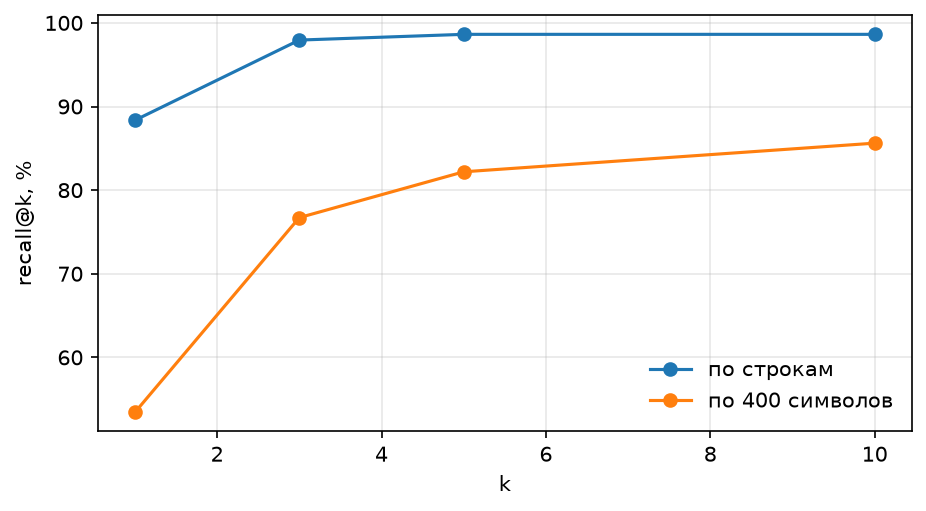

,нарезка,поиск,recall@1,recall@5
0,по 400 символов,только вектор,0.53,0.82
1,по 400 символов,только слова,0.78,0.92
2,по 400 символов,гибрид RRF,0.73,0.90
3,по строкам,только вектор,0.88,0.99
4,по строкам,только слова,0.90,0.98
5,по строкам,гибрид RRF,0.90,1.00


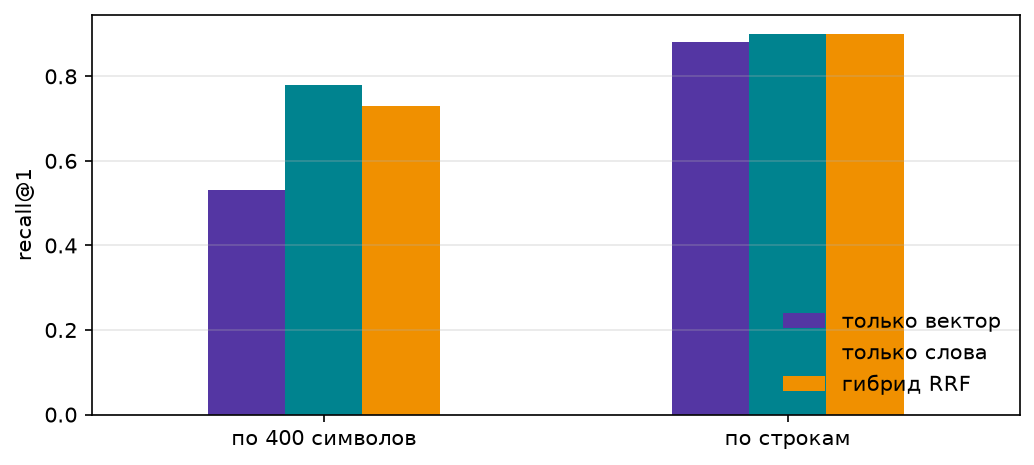

chosen k = 5 | recall@5 на построчной нарезке почти saturates; дальше дорогой контекст почти не растёт.


In [5]:
import json
display(Markdown("```json\n" + Path("index_meta.json").read_text(encoding="utf-8") + "\n```"))
display(Image(filename="img/recall_at_k.png"))
display(pd.read_csv("hybrid_table.csv"))
display(Image(filename="img/hybrid_recall.png"))
meta = json.loads(Path("index_meta.json").read_text())
print("chosen k =", meta.get("chosen_k"), "|", meta.get("chosen_k_reason"))

## Замер ответов

```
                         config             model  n  accuracy  cost_per_task  cost_per_correct
      сильная, без инструментов claude-sonnet-4.6 50      0.04        0.00102           0.02560
       дешёвая, живой поиск ДЗ1       gpt-4o-mini 50      0.12        0.00009           0.00078
            дешёвая, RAG всегда       gpt-4o-mini 50      0.74        0.00005           0.00007
дешёвая, агент с knowledge_base       gpt-4o-mini 50      0.88        0.00014           0.00016
            средняя, RAG всегда  claude-haiku-4.5 50      0.96        0.00064           0.00066
```

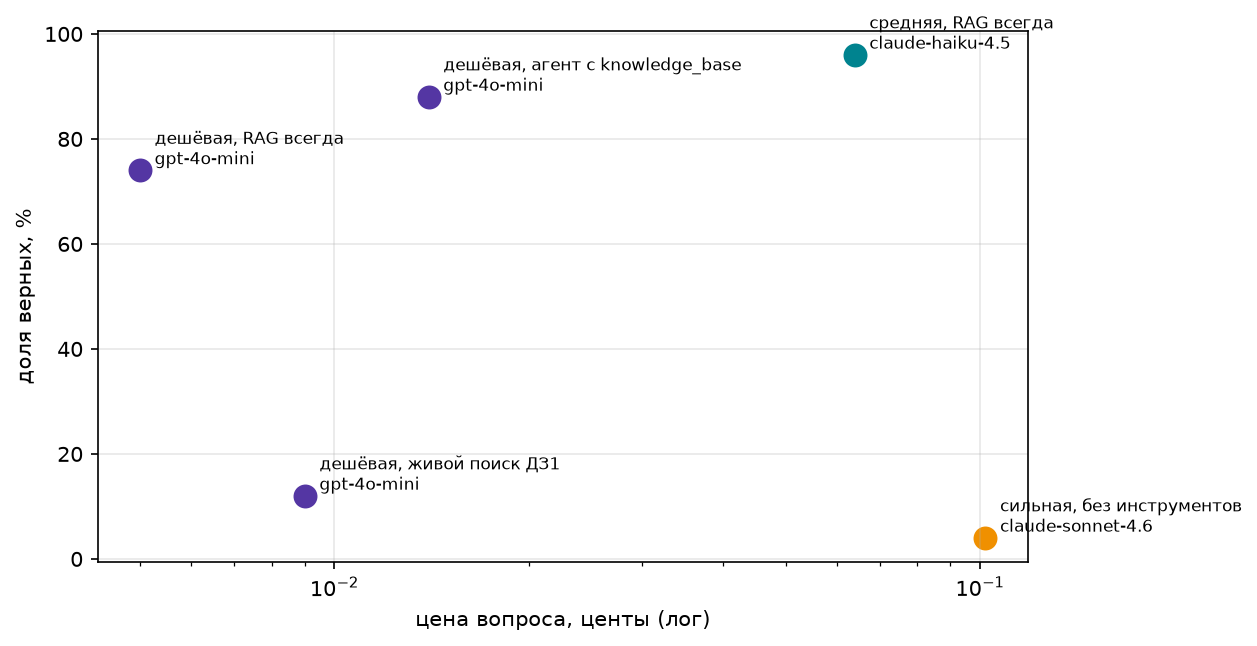

refusals:


{'unanswerable_total': 10,
 'unanswerable_refused': 10,
 'answerable_n': 50,
 'answerable_false_refuse': 1}

In [6]:
display(Markdown("```\n" + Path("results_rag.md").read_text(encoding="utf-8") + "\n```"))
display(Image(filename="img/money_rag.png"))
print("refusals:")
display(json.loads(Path("refusals.json").read_text())["summary"])

## Провалы

In [7]:
fail = json.loads(Path("failures_rag.json").read_text(encoding="utf-8"))
print("counts:", fail["counts"])
for kind in ("search_miss", "found_but_wrong"):
    row = (fail.get(kind) or [None])[0]
    if not row:
        print(kind, ": нет примеров"); continue
    print("\n===", kind, "===")
    print("id:", row.get("id"), "| gold:", row.get("gold"), "| answer:", row.get("answer"))
    print("q:", row.get("question"))
    print("found:", row.get("found"), "| refused:", row.get("refused"))

counts: {'search_miss': 10, 'found_but_wrong': 3}

=== search_miss ===
id: fresh-2 | gold: Miguel Díaz-Canel | answer: NOT_FOUND
q: Who entered negotiations with the Trump administration on March 13, 2026?
found: False | refused: True

=== found_but_wrong ===
id: fresh-5 | gold: two people | answer: 2
q: How many people were killed in the car incident in Leipzig, Germany in May 2026?
found: True | refused: False


## Память: тесты без LLM + факты

  embedded 2/2


  embedded 1/1


  embedded 1/1


memory tests without LLM: ok
facts s1: ["User's name is Anya", 'User lives in Berlin', 'User prefers short answers']
s2 answer: Ты живешь в Берлине. Информации о победителе Masters 2026 нет.
facts after move: ["User's name is Anya", 'User lives in Paris', 'User prefers short answers']


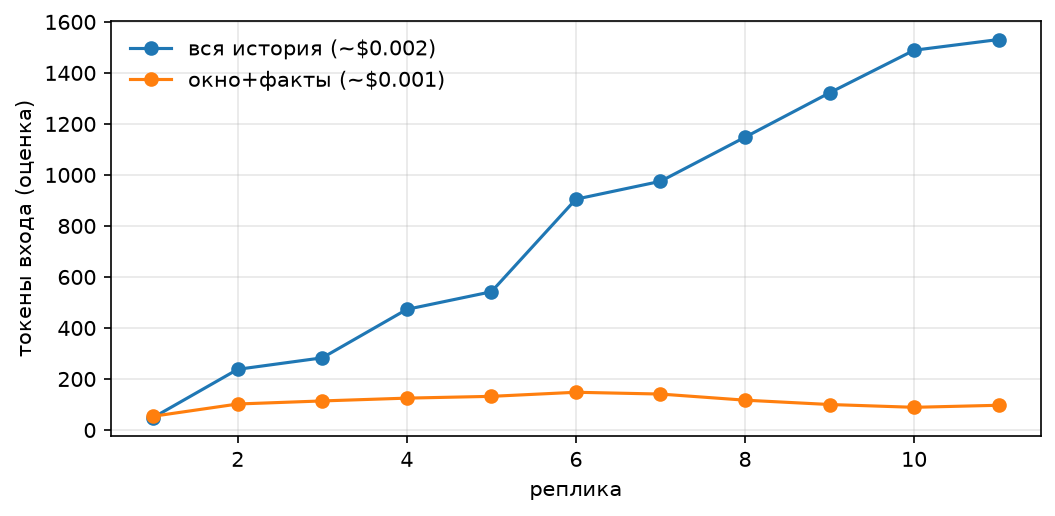

In [8]:
hw2.test_memory_without_llm()
demo = json.loads(Path("memory_demo.json").read_text(encoding="utf-8"))
print("facts s1:", demo["facts_s1"])
print("s2 answer:", demo["answer_s2"][:300])
print("facts after move:", demo["facts_after_move"])
display(Image(filename="img/tokens_memory.png"))

## Бонусы: parent-chunk и PDF

In [9]:
display(pd.read_csv("parent_chunk_table.csv"))
display(pd.read_csv("parent_rag_compare.csv"))
demos = json.loads(Path("pdf_demos.json").read_text(encoding="utf-8"))
for d in demos:
    print(d["question"])
    print(" ", hw2.final_answer(d["answer"])[:160])
    print("  sources:", d["sources"], "\n")

,режим,recall@1,recall@5
0,child (строка),0.82,0.97
1,parent (±2 строки),0.90,0.97


,config,model,n,accuracy,cost_per_task,cost_per_correct
0,RAG child,gpt-4o-mini,20,0.90,0.00007,0.00007
1,RAG parent,gpt-4o-mini,20,0.85,0.00017,0.00020


Что такое RRF и зачем он нужен?
  RRF — метод объединения результатов поиска для улучшения итогового рейтинга.
  sources: [['lecture06.pdf', 'стр. 14'], ['lecture06.pdf', 'стр. 19'], ['lecture05.pdf', 'стр. 24']] 

Какая доля верных ответов Sonnet допустима по критерию свежести?
  20 процентов.
  sources: [['homework01.pdf', 'стр. 1'], ['lecture06.pdf', 'стр. 17'], ['homework01.pdf', 'стр. 2']] 

Сколько баллов дают за два разобранных провала?
  NOT_FOUND
  sources: [['lecture06.pdf', 'стр. 19'], ['lecture06.pdf', 'стр. 13'], ['lecture06.pdf', 'стр. 14']] 



## Живой RAG-ответ (smoke)

In [10]:
q = tasks[3]["question"]
out = hw2.rag_answer(q, hw2.MODELS["cheap"], k=5, name="lines")
print("Q:", q)
print("gold:", tasks[3]["answer"])
print(out["answer"])
print("cost cents:", round(out["cost"] * 100, 4))
print("correct:", hw2.is_correct(tasks[3], out["answer"]))

Q: What agreement did Ukraine and Romania sign in March 2026?
gold: a strategic partnership agreement
Ukraine and Romania signed a strategic partnership agreement in the defense and energy sectors in March 2026 [1]. 

FINAL: strategic partnership agreement in defense and energy sectors.
cost cents: 0.0059
correct: True
